<div dir="rtl">

# הרצאה 4: עדויות לחומר אפל

**מה במחברת.** משפט הוויריאל ל-Coma, קריסה כדורית ($\delta_c=1.686$, $18\pi^2$), טיעון התזמון לקבוצה המקומית, והתאמה של עקומת סיבוב עם דיסקה, הילת NFW, הילת Burkert ו-MOND.

יחידות: $G=4.30091\times10^{-6}\,\mathrm{kpc\,(km/s)^2}/M_\odot$.

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
c = 299792.458            # km/s

from scipy.optimize import curve_fit
from scipy.special import i0, i1, k0, k1
G = 4.30091e-6           # kpc (km/s)^2 / Msun
G_Mpc = G*1e-3           # Mpc (km/s)^2 / Msun
kms_Gyr_in_Mpc = 1.0227e-3   # 1 km/s * 1 Gyr = 1.0227 pc

<div dir="rtl">

## 1. Zwicky ו-Coma
לכדור אחיד: $M=5\sigma_{\rm los}^2R/G$ (‏$2K+W=0$, $K=\tfrac32M\sigma_{\rm los}^2$, $W=-\tfrac35GM^2/R$).

</div>

In [2]:
sig, R, L = 1000.0, 1500.0, 5e12      # km/s, kpc, Lsun
M = 5*sig**2*R/G
print(f"M_Coma = {M:.2e} Msun,  M/L = {M/L:.0f} Msun/Lsun  (stars: ~ 3-5)")

M_Coma = 1.74e+15 Msun,  M/L = 349 Msun/Lsun  (stars: ~ 3-5)


<div dir="rtl">

## 2. קריסה כדורית
קליפה סגורה מתפתחת כציקלואידה: $r=A(1-\cos\theta)$, $t=B(\theta-\sin\theta)$, $A^3=GMB^2$. מכאן שתי התוצאות המרכזיות (ב-EdS):

* בקריסה ($\theta=2\pi$) ההפרעה הליניארית היא $\delta_L=\tfrac{3}{20}(12\pi)^{2/3}=1.686$.
* אחרי וויריאליזציה ($r_{\rm vir}=r_{\max}/2$) הצפיפות היא $18\pi^2\approx178$ פעמים הממוצע.

נבדוק נומרית את $\delta_{\rm NL}(\theta)$ מול $\delta_L(\theta)$:

</div>

delta_L at collapse  = 1.6865
delta_L at turnaround = 1.0624,  delta_NL = 4.552
Delta_vir = 18 pi^2 = 177.7


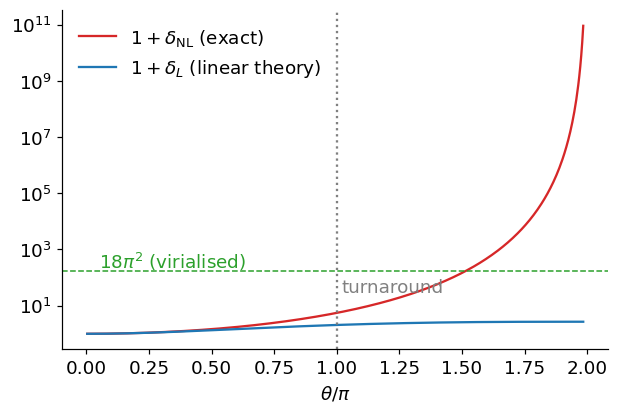

In [3]:
th = np.linspace(0.01, 2*np.pi - 0.05, 500)
delta_NL = 4.5*(th - np.sin(th))**2/(1 - np.cos(th))**3 - 1
delta_L = 0.6*(0.75*(th - np.sin(th)))**(2/3)
print(f"delta_L at collapse  = {0.6*(0.75*2*np.pi)**(2/3):.4f}")
print(f"delta_L at turnaround = {0.6*(0.75*np.pi)**(2/3):.4f},  delta_NL = {4.5*np.pi**2/8 - 1:.3f}")
print(f"Delta_vir = 18 pi^2 = {18*np.pi**2:.1f}")
fig, ax = plt.subplots(figsize=(6.4, 4))
ax.semilogy(th/np.pi, 1 + delta_NL, "C3", label=r"$1+\delta_{\rm NL}$ (exact)")
ax.semilogy(th/np.pi, 1 + delta_L, "C0", label=r"$1+\delta_L$ (linear theory)")
ax.axvline(1, color="gray", ls=":"); ax.text(1.02, 30, "turnaround", color="gray")
ax.axhline(178, color="C2", ls="--", lw=1); ax.text(0.05, 220, r"$18\pi^2$ (virialised)", color="C2")
ax.set_xlabel(r"$\theta/\pi$"); ax.legend(frameon=False); plt.show()

<div dir="rtl">

## 3. טיעון התזמון: המסה של הקבוצה המקומית
שביל החלב ואנדרומדה ($r=0.77\,$Mpc, $v_r=-109\,$km/s) התרחקו זה מזה מאז המפץ, נעצרו, ועכשיו מתקרבים. אם זו קריסה רדיאלית בגיל $t_0=13.8\,$Gyr:
$$\frac{v\,t}{r}=\frac{\sin\theta(\theta-\sin\theta)}{(1-\cos\theta)^2},\qquad M=\frac{A^3}{GB^2}.$$
פותרים עבור $\theta\in(\pi,2\pi)$ (שלב הקריסה).

</div>

In [4]:
r_LG, v_LG, t0 = 0.77, -109.0, 13.8          # Mpc, km/s, Gyr
target = v_LG*t0*kms_Gyr_in_Mpc/r_LG
g = lambda th: np.sin(th)*(th - np.sin(th))/(1 - np.cos(th))**2 - target
theta = brentq(g, np.pi + 1e-3, 2*np.pi - 1e-3)
A = r_LG/(1 - np.cos(theta)); B = t0/(theta - np.sin(theta))      # Mpc, Gyr
B_u = B*kms_Gyr_in_Mpc                                             # Gyr -> Mpc/(km/s)
M_LG = A**3/(G_Mpc*B_u**2)
print(f"vt/r = {target:.3f}  ->  theta = {theta:.3f} rad = {theta/np.pi:.3f} pi")
print(f"r_max = {2*A:.2f} Mpc reached {B*np.pi:.1f} Gyr after the Big Bang")
print(f"M_LG = {M_LG:.2e} Msun   (stars+gas of MW+M31: ~2e11)")

vt/r = -1.998  ->  theta = 4.202 rad = 1.337 pi
r_max = 1.03 Mpc reached 8.5 Gyr after the Big Bang
M_LG = 4.16e+12 Msun   (stars+gas of MW+M31: ~2e11)


<div dir="rtl">

## 4. עקומת סיבוב: דיסקה + הילה
דיסקה אקספוננציאלית (Freeman), ועוד אחת משלוש אפשרויות: הילת NFW ($\rho\propto 1/[x(1+x)^2]$, קוספ), הילת Burkert (ליבה), או MOND בלי חומר אפל. הנתונים סינתטיים: נוצרו מדיסקה+NFW עם רעש.

</div>

NFW:     log rho_s = 6.73 ± 0.16,  r_s = 22.9 ± 5.1 kpc,  chi2 = 31.8 / 20
Burkert: log rho_0 = 7.62,  r_0 = 7.8 kpc,  chi2 = 45.7 / 20
MOND (a0 fixed):  chi2 = 48.1 / 22


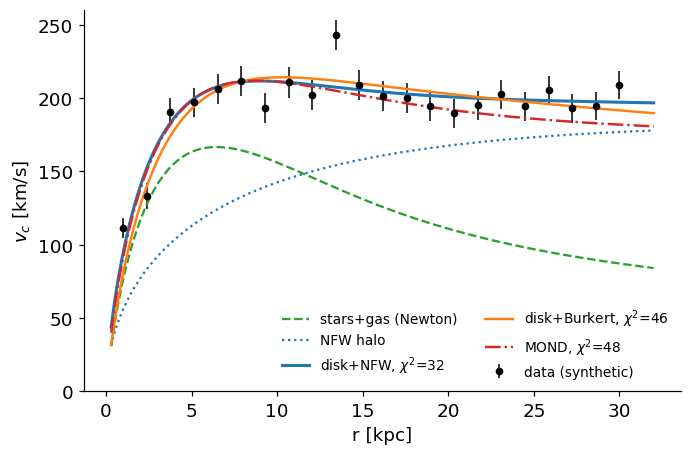

In [5]:
def v_disk(r, Md=5e10, Rd=3.0):
    y = r/(2*Rd); Sig0 = Md/(2*np.pi*Rd**2)
    return np.sqrt(4*np.pi*G*Sig0*Rd*y**2*(i0(y)*k0(y) - i1(y)*k1(y)))
def m_nfw(r, rho_s, r_s):
    x = r/r_s; return 4*np.pi*rho_s*r_s**3*(np.log(1 + x) - x/(1 + x))
def m_bur(r, rho_0, r_0):
    x = r/r_0; return np.pi*rho_0*r_0**3*(np.log((1 + x**2)*(1 + x)**2) - 2*np.arctan(x))
v_nfw_tot = lambda r, lrho, rs: np.sqrt(v_disk(r)**2 + G*m_nfw(r, 10**lrho, rs)/r)
v_bur_tot = lambda r, lrho, r0: np.sqrt(v_disk(r)**2 + G*m_bur(r, 10**lrho, r0)/r)
def v_mond(r, a0=1.2e-10):
    a0k = a0/3.241e-14                     # m/s^2 -> (km/s)^2/kpc
    gN = v_disk(r)**2/r
    return np.sqrt((gN/2 + np.sqrt(gN**2/4 + gN*a0k))*r)

rng = np.random.default_rng(3)
r = np.linspace(1.0, 30.0, 22)
v_true = v_nfw_tot(r, np.log10(8e6), 18.0)
err = 4.0 + 0.03*v_true
v_obs = v_true + err*rng.normal(size=r.size)

pN, cN = curve_fit(v_nfw_tot, r, v_obs, p0=[7, 15], sigma=err, absolute_sigma=True)
pB, cB = curve_fit(v_bur_tot, r, v_obs, p0=[7.5, 5], sigma=err, absolute_sigma=True)
chi = lambda model: np.sum(((v_obs - model)/err)**2)
chiN, chiB, chiM = chi(v_nfw_tot(r, *pN)), chi(v_bur_tot(r, *pB)), chi(v_mond(r))
print(f"NFW:     log rho_s = {pN[0]:.2f} ± {np.sqrt(cN[0,0]):.2f},  r_s = {pN[1]:.1f} ± {np.sqrt(cN[1,1]):.1f} kpc,  chi2 = {chiN:.1f} / {r.size-2}")
print(f"Burkert: log rho_0 = {pB[0]:.2f},  r_0 = {pB[1]:.1f} kpc,  chi2 = {chiB:.1f} / {r.size-2}")
print(f"MOND (a0 fixed):  chi2 = {chiM:.1f} / {r.size}")

rr = np.linspace(0.3, 32, 300)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(r, v_obs, err, fmt="o", color="k", ms=4, lw=1, label="data (synthetic)")
ax.plot(rr, v_disk(rr), "C2--", label="stars+gas (Newton)")
ax.plot(rr, np.sqrt(G*m_nfw(rr, 10**pN[0], pN[1])/rr), "C0:", label="NFW halo")
ax.plot(rr, v_nfw_tot(rr, *pN), "C0", lw=2, label=rf"disk+NFW, $\chi^2$={chiN:.0f}")
ax.plot(rr, v_bur_tot(rr, *pB), "C1", lw=1.6, label=rf"disk+Burkert, $\chi^2$={chiB:.0f}")
ax.plot(rr, v_mond(rr), "C3-.", lw=1.6, label=rf"MOND, $\chi^2$={chiM:.0f}")
ax.set_xlabel("r [kpc]"); ax.set_ylabel(r"$v_c$ [km/s]"); ax.set_ylim(0, 260)
ax.legend(fontsize=9, frameon=False, ncol=2, loc="lower right"); plt.show()

<div dir="rtl">

**שימו לב.** הנתונים נוצרו מדיסקה+NFW, ו-NFW אכן נותן את ה-$\chi^2$ הנמוך ביותר. ההבדל ל-Burkert ($\Delta\chi^2\approx14$) בא מכמה נקודות בודדות, ובנתונים אמיתיים, עם שגיאות סיסטמטיות, קשה להבחין כך בין קוספ לליבה. MOND, עם $a_0$ קבוע ובלי שום פרמטר חופשי, נותן עקומה שטוחה ברמה הנכונה. זה מה שהופך אותו לאתגר מעניין בגלקסיות (אבל לא בצבירים ובקוסמולוגיה).

---
# תרגילים פתורים נוספים

### תרגיל א: ההילה של שביל החלב
הילת NFW עם $M_{200}=1.2\times10^{12}M_\odot$ ו-$c=10$, ב-$h=0.674$. חשבו $r_{200}$, $v_{200}$, $r_s$, את $v_{\max}$ ואיפה היא מתקבלת, ואת $v_c$ ב-$8\,$kpc (בלי הדיסקה).

</div>

In [6]:
H0k = 0.0674                                      # km/s/kpc
mu = lambda x: np.log(1 + x) - x/(1 + x)
M200, cc = 1.2e12, 10
r200 = (G*M200/(100*H0k**2))**(1/3); v200 = np.sqrt(G*M200/r200); rs = r200/cc
x_max = brentq(lambda x: np.log(1 + x) - x*(1 + 2*x)/(1 + x)**2, 1, 5)
vc = lambda rr: np.sqrt(G*M200*mu(rr/rs)/mu(cc)/rr)
print(f"r200 = {r200:.0f} kpc,  v200 = {v200:.0f} km/s,  r_s = {rs:.1f} kpc")
print(f"v_max = {vc(x_max*rs):.0f} km/s at r = {x_max:.3f} r_s = {x_max*rs:.0f} kpc")
print(f"v_c(8 kpc) from the halo alone = {vc(8):.0f} km/s   (observed ~ 230: the disk supplies the rest)")

r200 = 225 kpc,  v200 = 152 km/s,  r_s = 22.5 kpc
v_max = 183 km/s at r = 2.163 r_s = 49 kpc
v_c(8 kpc) from the halo alone = 135 km/s   (observed ~ 230: the disk supplies the rest)


<div dir="rtl">

### תרגיל ב: רגישות טיעון התזמון
איך משתנה $M_{\rm LG}$ עם $t_0$ ועם $v_r$? (שימו לב שהמסה לא תלויה במהירות המשיקית בקירוב הרדיאלי, אבל מדידות Gaia נותנות $v_t\sim50$-$80\,$km/s.)

</div>

In [7]:
def M_timing(r=0.77, v=-109.0, t=13.8):
    tgt = v*t*kms_Gyr_in_Mpc/r
    th = brentq(lambda th: np.sin(th)*(th - np.sin(th))/(1 - np.cos(th))**2 - tgt, np.pi + 1e-4, 2*np.pi - 1e-4)
    A = r/(1 - np.cos(th)); B = t/(th - np.sin(th))*kms_Gyr_in_Mpc
    return A**3/(G_Mpc*B**2)
for t in (12.0, 13.8, 15.0):
    print(f"t0 = {t:4.1f} Gyr:  M = {M_timing(t=t):.2e}")
for v in (-90.0, -109.0, -130.0):
    print(f"v_r = {v:6.1f} km/s: M = {M_timing(v=v):.2e}")

t0 = 12.0 Gyr:  M = 4.70e+12
t0 = 13.8 Gyr:  M = 4.16e+12
t0 = 15.0 Gyr:  M = 3.88e+12
v_r =  -90.0 km/s: M = 3.36e+12
v_r = -109.0 km/s: M = 4.16e+12
v_r = -130.0 km/s: M = 5.13e+12


<div dir="rtl">

### תרגיל ג: יחס טולי-פישר מ-MOND
ב-MOND, הרחק מהמרכז $g=\sqrt{g_Na_0}$, ולכן $v^4=GMa_0$: יחס טולי-פישר הבריוני יוצא אוטומטית. חשבו $v_{\rm flat}$ לגלקסיה עם $M_b=5\times10^{10}M_\odot$ והשוו לעקומה למעלה ב-$r=30\,$kpc.

</div>

In [8]:
a0k = 1.2e-10/3.241e-14
v_flat = (G*5e10*a0k)**0.25
print(f"v_flat (MOND) = {v_flat:.0f} km/s;   MOND curve at 30 kpc: {v_mond(30.0):.0f} km/s;   at 100 kpc: {v_mond(100.0):.0f} km/s")

v_flat (MOND) = 168 km/s;   MOND curve at 30 kpc: 182 km/s;   at 100 kpc: 171 km/s
